In [157]:
# 2
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


quiz_data = pd.DataFrame({
 "study_hours":
[4.8,11.4,8.9,7.4,2.3,2.3,1.2,10.5,7.4,8.6,0.7,11.7,10.1,2.9,2.6,2.6,4.0,6.5,5.5,3.8,7.5,2.1,3.9,4.7,5.7,9.5,
 2.8,6.4,7.3,1.0,7.5,2.5,1.2,11.4,11.6,9.8,4.0,1.6,8.4,5.6,1.9,6.2,0.9,11.0,3.5,8.1,4.1,6.5,6.8,2.6,11.7,9.4,
 11.3,10.8,7.4,11.1,1.5,2.8,1.0,4.2],
 "videos_watched":
[15,12,17,14,20,23,24,12,8,14,12,0,24,6,8,
23,0,11,7,23,10,18,16,7,2,2,0,4,9,6,8,6,8,7,11,1,0,15,22,22,23,4,2,
11,7,21,2,0,2,4,14,13,2,0,4,22,13,6,8,14],
 "practice_solved":
[14,25,12,31,38,31,3,29,36,22,38,14,28,35,12,31,6,21,27,1,5,27,
27,19,29,10,27,24,38,32,0,26,12,2,38,5,7,26
,8,36,32,23,14,31,31,23,11,38,1,2,36,16,1,1,27,22,36,31,32,0],
 "quiz_score":
[59.7,94.2,82.2,83.1,72.2,62.8,43.3,97.3,78.1,88.6,61.2,86.6,97.9,59.2,43.3,72.4,48.4,
74.1,66.6,54.6,67.3,55.2,68.7,54.5,67.1,69.7,47.2,62.9,81.4,50.7,64.3,53.8,44.5,88.3,
100.0,67.1,36.4,59.6,85.4,80.9,68.6,69.8,35.0,100.0,60.6,82.2,50.8,77.4,55.7,32.3,
100.0,77.8,76.1,74.3,74.4,100.0,55.3,56.6,44.6,47.0]
})
quiz_data

,study_hours,videos_watched,practice_solved,quiz_score
0,4.8,15,14,59.7
1,11.4,12,25,94.2
2,8.9,17,12,82.2
3,7.4,14,31,83.1
4,2.3,20,38,72.2
5,2.3,23,31,62.8
6,1.2,24,3,43.3
7,10.5,12,29,97.3
8,7.4,8,36,78.1
9,8.6,14,22,88.6


In [158]:
print(quiz_data.shape)
quiz_data.head()

(60, 4)


,study_hours,videos_watched,practice_solved,quiz_score
0,4.8,15,14,59.7
1,11.4,12,25,94.2
2,8.9,17,12,82.2
3,7.4,14,31,83.1
4,2.3,20,38,72.2


In [159]:
X = quiz_data[["study_hours","videos_watched","practice_solved"]]
y = quiz_data["quiz_score"]
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=42)
print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(X_test.shape)

(48, 3)
(12, 3)
(48,)
(12, 3)


In [160]:
model = LinearRegression()
model.fit(X_train,y_train)

y_pred=model.predict(X_test)


In [162]:
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("MAE:", mae)
print("MSE:", mse)
print("R2 :", r2)

MAE: 3.5647757861145433
MSE: 19.96130798119171
R2 : 0.9445055055831497


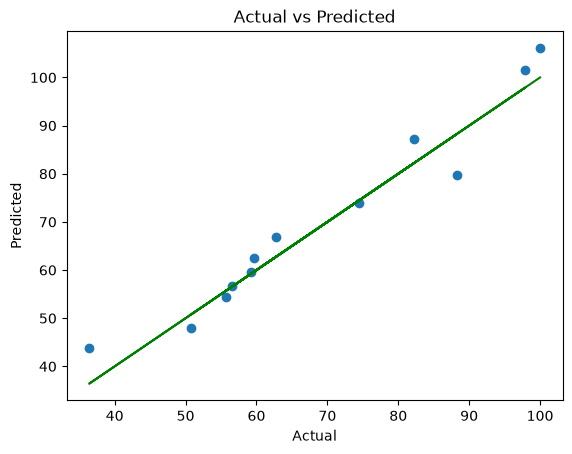

In [163]:
plt.scatter(y_test, y_pred)
plt.plot(y_test, y_test,color="green")
plt.xlabel("Actual")
plt.ylabel("Predicted")
plt.title("Actual vs Predicted")
plt.show()

In [164]:
print(model.coef_) #3features
print(model.intercept_) #b

[4.56345872 0.73498918 0.58595905]
21.403060901427324


In [165]:
X2 = X.drop(columns="videos_watched")
X2_train, X2_test, y2_train, y2_test = train_test_split(X2, y, test_size=0.2, random_state=42)

model2 = LinearRegression()
model2.fit(X2_train, y2_train)
y2_pred=model2.predict(X2_test)
new_r2= r2_score(y2_test, y2_pred)
print("without videos:",new_r2)
print(r2)


without videos: 0.8961631518766293
0.9445055055831497


In [ ]:
# 3
import pandas as pd
import numpy as np

import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score,f1_score, confusion_matrix, classification_report)
from sklearn.metrics import ConfusionMatrixDisplay

gym_data = pd.DataFrame({
 "visits_per_month":
[6,5,0,4,15,12,18,4,17,6,6,0,11,18,8,0,16,12,16,14,17,13,3,19,13,15,15,4,0,16,18,15,0,11,4,0,0,5,17,
15,17,10,0,6,5,10,14,4,13,19,6,7,17,4,5,17,3,7,0,12,19,12,1,14,13,9,11,6,8,19,12,8,10,17,14,5,12,7,
2,4,14,12,9,16,11,9,3,10,4,16],
 "avg_session_min":
[51.1,40.8,15.4,74.2,42.2,44.3,26.8,54.0,66.4,56.7,25.1,18.6,66.3,73.9,48.1,13.9,40.4,27.1,49.5,51.0
,42.2,51.2,13.4,43.6,54.7,49.9,74.3,47.5,11.3,25.4,51.7,47.2,12.6,32.4,54.5,11.0,13.1,28.6,33.4,45.6
,38.9,64.9,24.3,58.1,42.0,72.3,66.1,53.3,64.1,25.1,68.6,52.4,49.4,63.6,63.1,62.6,17.9,71.0,13.2,50.1
,59.8,48.8,22.6,27.8,49.8,30.3,51.6,56.8,33.3,54.3,31.1,52.9,35.4,65.0,37.1,47.1,73.8,59.7,12.0,59.5
,72.2,52.2,62.6,51.2,37.1,46.4,16.8,39.4,37.3,42.7],
 "days_since_last_visit":
[8,10,21,1,10,11,8,1,14,3,7,41,1,6,14,20,8,7,12,14,2,14,23,12,7,4,10,5,46,4,11,4,58,11,10,26,49,4,14,
5,13,5,43,13,10,7,1,5,2,13,14,11,1,12,3,7,27,3,25,9,1,5,27,11,8,4,9,0,9,5,12,10,5,1,4,2,12,10,55,10,
8,14,13,8,3,11,34,12,6,8],
 "has_personal_trainer":
[1,1,0,1,1,0,1,1,1,1,1,0,1,0,1,0,1,1,0,1,1,1,1,1,1,1,0,1,0,1,0,0,0,0,0,1,0,1,0,1,0,0,0,0,0,1,0,1,0,1,1,1,1,
1,0,1,0,1,0,1,1,1,1,1,1,0,1,0,1,1,1,1,1,1,1,0,1,0,1,0,1,1,0,1,1,0,1,1,0,0],
 "churned":
[0,0,1,0,0,0,0,0,0,0,0,1,0,0,0,1,0,0,0,0,0,0,1,0,0,0,0,0,1,0,0,0,1,0,0,1,1,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,
0,0,0,1,0,1,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,1,0,0,0]
})
gym_data


,visits_per_month,avg_session_min,days_since_last_visit,has_personal_trainer,churned
0,6,51.1,8,1,0
1,5,40.8,10,1,0
2,0,15.4,21,0,1
3,4,74.2,1,1,0
4,15,42.2,10,1,0
...,...,...,...,...,...
85,9,46.4,11,0,0
86,3,16.8,34,1,1
87,10,39.4,12,1,0
88,4,37.3,6,0,0


In [167]:
gym_data.head()

,visits_per_month,avg_session_min,days_since_last_visit,has_personal_trainer,churned
0,6,51.1,8,1,0
1,5,40.8,10,1,0
2,0,15.4,21,0,1
3,4,74.2,1,1,0
4,15,42.2,10,1,0


In [168]:
print(gym_data["churned"].value_counts())


churned
0    76
1    14
Name: count, dtype: int64


In [169]:
print(gym_data["churned"].value_counts(normalize=True) * 100)

churned
0    84.444444
1    15.555556
Name: proportion, dtype: float64


In [170]:
X = gym_data.drop(columns="churned")
y = gym_data["churned"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(X_test.shape)

(72, 4)
(18, 4)
(72,)
(18, 4)


In [171]:
scaler=StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
model = LogisticRegression()
model.fit(X_train_scaled, y_train)


,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following

In [172]:
y_pred = model.predict(X_test_scaled)

In [173]:
accuracy = accuracy_score(y_test,y_pred)
precision = precision_score(y_test,y_pred)
recall = recall_score(y_test,y_pred)
f1 = f1_score(y_test,y_pred)
print("accuracy : ",accuracy)
print("precision : ",precision)
print("recall : ",recall)
print("f1 : ",f1)

accuracy :  1.0
precision :  1.0
recall :  1.0
f1 :  1.0


In [174]:
cm = confusion_matrix(y_test, y_pred)
print(cm)




[[15  0]
 [ 0  3]]


In [ ]:
proba = model.predict_proba(X_test_scaled)[:, 1]     
y_pred_03 = (proba >= 0.3).astype(int)

print(recall_score(y_test, y_pred_03))
print(precision_score(y_test, y_pred_03))

1.0
1.0


In [ ]:
proba = model.predict_proba(X_test_scaled)[:, 1]    
y_pred_05 = (proba >= 0.5).astype(int)

print(recall_score(y_test, y_pred_05))
print(precision_score(y_test, y_pred_05))

1.0
1.0


In [ ]:
# 4
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


flight_data = pd.DataFrame({
 "days_before_flight":
[26,64,81,82,56,14,77,34,72,83,25,49,33,46,5,35,13,2,75,38,85,82,25,18,68,71,44,65,80,24,
28,71,11,58,28,45,15,8,56,80,65,41,28,6,54,72,51,60,2,4,9,88,82,69,73],
 "distance_km":
[575,2245,1234,3510,2458,1752,564,1229,685,1291,4245,718,319,3456,2142,743,793,1140,
1362,2259,419,4258,4171,3104,3216,3504,2533,2669,2088,4486,930,4032,662,3818,4016,3190,
4378,1985,1231,2813,2866,4244,2077,614,3949,1424,4340,1105,1929,2600,3550,4009,2305,2051,2358],
 "num_stops":
[0,1,0,1,0,0,2,2,2,0,0,2,0,1,1,1,0,1,2,2,2,2,0,1,2,2,0,0,2,1,1,2,0,1,1,2,2,1,2,2,1,1,0,2,1,2,1,0,1,0,2,0,2,2,1],
 "ticket_price_usd":
[335,380,275,391,458,431,61,331,133,233,683,214,308,506,476,298,402,480,162,390,63,
425,705,569,368,400,474,375,233,703,354,443,380,492,571,475,663,495,207,287,401,595,453,357,544,189,
552,254,476,609,611,456,224,246,315]
})
flight_data

,days_before_flight,distance_km,num_stops,ticket_price_usd
0,26,575,0,335
1,64,2245,1,380
2,81,1234,0,275
3,82,3510,1,391
4,56,2458,0,458
5,14,1752,0,431
6,77,564,2,61
7,34,1229,2,331
8,72,685,2,133
9,83,1291,0,233


In [178]:
X = flight_data[["days_before_flight", "distance_km", "num_stops"]]
y = flight_data["ticket_price_usd"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(X_test.shape)

(44, 3)
(11, 3)
(44,)
(11, 3)


In [179]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled  = scaler.transform(X_test)

knn_model = KNeighborsRegressor(n_neighbors=5)
knn_model.fit(X_train_scaled, y_train)
y_pred= knn_model.predict(X_test_scaled)


In [91]:
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("MAE:", mae)
print("MSE:", mse)
print("R2 :", r2)

MAE: 34.309090909090905
MSE: 2498.650909090909
R2 : 0.7947055268629414


In [97]:

k = [1, 3, 5, 7, 9, 15]

results = []

for i in k:

    knn_model = KNeighborsRegressor(n_neighbors=i)
    knn_model.fit(X_train_scaled, y_train)
    y_pred = knn_model.predict(X_test_scaled)
    r2 = r2_score(y_test, y_pred)

    results.append({
        'K': i,
        'R2': r2
    })

results_df = pd.DataFrame(results)
print(results_df)

    K        R2
0   1  0.705613
1   3  0.769163
2   5  0.794706
3   7  0.762208
4   9  0.854028
5  15  0.730370


In [180]:
knn_model = KNeighborsRegressor(n_neighbors=9)

knn_model.fit(X_train_scaled, y_train)

flight = [[20, 2000, 1]]

flight_scaled = scaler.transform(flight)

price = knn_model.predict(flight_scaled)

print(price,"$")

[436.88888889] $


/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/utils/validation.py:2830: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


In [ ]:
# 5
from sklearn.datasets import make_classification
from sklearn.tree import DecisionTreeClassifier

X, y = make_classification(
 n_samples=400,
 n_features=4,
 n_informative=3,
 n_redundant=0,
 n_clusters_per_class=2,
 weights=[0.82, 0.18], 
 flip_y=0.05, 
 class_sep=0.9,
 random_state=42
)
feature_names = ['accuracy_pct', 'reaction_time_ms', 'headshot_rate_pct', 'reports_count']

In [110]:
X_train, X_test, y_train, y_test = train_test_split(X, y,test_size=0.3,random_state=42,stratify=y)

print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(X_test.shape)

(280, 4)
(120, 4)
(280,)
(120, 4)


In [ ]:
# DecisionTreeClassifier(max_depth=1, random_state=42) 
# DecisionTreeClassifier(max_depth=4, random_state=42)
# DecisionTreeClassifier(random_state=42) 

In [ ]:

# model1 = DecisionTreeClassifier(max_depth=1, random_state=42)
# model1.fit(X_train, y_train)


# model2 = DecisionTreeClassifier(max_depth=4, random_state=42)
# model2.fit(X_train, y_train)


# model3 = DecisionTreeClassifier(random_state=42)
# model3.fit(X_train, y_train)

In [116]:
# max_depth=1

model1 = DecisionTreeClassifier(max_depth=1, random_state=42)
model1.fit(X_train, y_train)

y_train_pred1 = model1.predict(X_train)
y_test_pred1 = model1.predict(X_test)

accuracy_train_model1=accuracy_score(y_train,y_train_pred1)
accuracy_test_model1=accuracy_score(y_test,y_test_pred1)
print("accuracy_train_model1 : ",accuracy_train_model1)
print("accuracy_test_model1 : ",accuracy_test_model1)

accuracy_train_model1 :  0.85
accuracy_test_model1 :  0.7583333333333333


In [117]:
# max_depth=4

model2 = DecisionTreeClassifier(max_depth=4, random_state=42)
model2.fit(X_train, y_train)

y_train_pred2 = model2.predict(X_train)
y_test_pred2 = model2.predict(X_test)

accuracy_train_model2=accuracy_score(y_train,y_train_pred2)
accuracy_test_model2=accuracy_score(y_test,y_test_pred2)
print("accuracy_train_model2 : ",accuracy_train_model2)
print("accuracy_test_model2 : ",accuracy_test_model2)

accuracy_train_model2 :  0.9607142857142857
accuracy_test_model2 :  0.85


In [118]:
# no limit

model3 = DecisionTreeClassifier(random_state=42)
model3.fit(X_train, y_train)

y_train_pred3 = model3.predict(X_train)
y_test_pred3 = model3.predict(X_test)

accuracy_train_model3=accuracy_score(y_train,y_train_pred3)
accuracy_test_model3=accuracy_score(y_test,y_test_pred3)
print("accuracy_train_model3 : ",accuracy_train_model3)
print("accuracy_test_model3 : ",accuracy_test_model3)

accuracy_train_model3 :  1.0
accuracy_test_model3 :  0.8166666666666667


In [120]:
print("max_depth 1 :")
print("accuracy_train_model1 : ",accuracy_train_model1)
print("accuracy_test_model1 : ",accuracy_test_model1)
print("---------------------------------------------")
print("max_depth 4 :")
print("accuracy_train_model2 : ",accuracy_train_model2)
print("accuracy_test_model2 : ",accuracy_test_model2)
print("---------------------------------------------")
print("no limit :")
print("accuracy_train_model3 : ",accuracy_train_model3)
print("accuracy_test_model3 : ",accuracy_test_model3)

max_depth 1 :
accuracy_train_model1 :  0.85
accuracy_test_model1 :  0.7583333333333333
---------------------------------------------
max_depth 4 :
accuracy_train_model2 :  0.9607142857142857
accuracy_test_model2 :  0.85
---------------------------------------------
no limit :
accuracy_train_model3 :  1.0
accuracy_test_model3 :  0.8166666666666667


In [185]:
#6
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt


listener_data = pd.DataFrame({
 "weekly_listening_hours":
[9.4,3.0,4.6,29.3,27.2,9.6,31.9,16.8,8.2,12.3,
4.7,8.8,32.3,8.2,21.8,1.4,5.8,25.3,22.7,22.2,
15.7,2.2,31.5,25.1,2.5,12.3,32.4,4.7,4.0,25.9,
4.8,3.3,2.2,4.4,11.1,12.7,17.6,11.5,24.2,17.1,
23.9,14.7,5.0,3.1,17.7,20.3,30.2,5.5],
 "followed_genres_count":
[5,1,3,11,14,7,11,7,4,8,1,4,12,7,12,3,1,14,11,
10,6,2,12,12,1,6,14,1,3,8,3,3,1,2,6,5,4,5,12,
5,14,5,2,3,7,8,12,3]
})
listener_data

,weekly_listening_hours,followed_genres_count
0,9.4,5
1,3.0,1
2,4.6,3
3,29.3,11
4,27.2,14
5,9.6,7
6,31.9,11
7,16.8,7
8,8.2,4
9,12.3,8


In [186]:
listener_data.head()

,weekly_listening_hours,followed_genres_count
0,9.4,5
1,3.0,1
2,4.6,3
3,29.3,11
4,27.2,14


In [187]:
scaler= StandardScaler()
listener_scaled=scaler.fit_transform(listener_data)

listener_scaled = pd.DataFrame(
    listener_scaled,
    columns=listener_data.columns
)
listener_scaled.head()

,weekly_listening_hours,followed_genres_count
0,-0.505717,-0.352337
1,-1.153306,-1.305135
2,-0.991409,-0.828736
3,1.507877,1.076860
4,1.295387,1.791458


In [191]:
kmeans = KMeans(n_clusters=3,n_init=10, random_state=42)

kmeans.fit(listener_scaled)

,"n_clusters n_clusters: int, default=8The number of clusters to form as well as the number ofcentroids to generate.For an example of how to choose an optimal value for `n_clusters` refer to:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_silhouette_analysis.py`.",3
,"n_init n_init: 'auto' or int, default='auto'Number of times the k-means algorithm is run with different centroidseeds. The final results is the best output of `n_init` consecutive runsin terms of inertia. Several runs are recommended for sparsehigh-dimensional problems (see :ref:`kmeans_sparse_high_dim`).When `n_init='auto'`, the number of runs depends on the value of init:10 if using `init='random'` or `init` is a callable;1 if using `init='k-means++'` or `init` is an array-like... versionadded:: 1.2 Added 'auto' option for `n_init`... versionchanged:: 1.4 Default value for `n_init` changed to `'auto'`.",10
,"random_state random_state: int, RandomState instance or None, default=NoneDetermines random number generation for centroid initialization. Usean int to make the randomness deterministic.See :term:`Glossary <random_state>`.",42
,"init init: {'k-means++', 'random'}, callable or array-like of shape (n_clusters, n_features), default='k-means++'Method for initialization:* 'k-means++' : selects initial cluster centroids using sampling based on an empirical probability distribution of the points' contribution to the overall inertia. This technique speeds up convergence. The algorithm implemented is ""greedy k-means++"". It differs from the vanilla k-means++ by making several trials at each sampling step and choosing the best centroid among them.* 'random': choose `n_clusters` observations (rows) at random from data for the initial centroids.* If an array is passed, it should be of shape (n_clusters, n_features) and gives the initial centers.* If a callable is passed, it should take arguments X, n_clusters and a random state and return an initialization.For an example of how to use the different `init` strategies, see:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_digits.py`.For an evaluation of the impact of initialization, see the example:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_stability_low_dim_dense.py`.",'k-means++'
,"max_iter max_iter: int, default=300Maximum number of iterations of the k-means algorithm for asingle run.",300
,"tol tol: float, default=1e-4Relative tolerance with regards to Frobenius norm of the differencein the cluster centers of two consecutive iterations to declareconvergence.",0.0001
,"verbose verbose: int, default=0Verbosity mode.",0
,"copy_x copy_x: bool, default=TrueWhen pre-computing distances it is more numerically accurate to centerthe data first. If copy_x is True (default), then the original data isnot modified. If False, the original data is modified, and put backbefore the function returns, but small numerical differences may beintroduced by subtracting and then adding the data mean. Note that ifthe original data is not C-contiguous, a copy will be made even ifcopy_x is False. If the original data is sparse, but not in CSR format,a copy will be made even if copy_x is False.",True
,"algorithm algorithm: {""lloyd"", ""elkan""}, default=""lloyd""K-means algorithm to use. The classical EM-style algorithm is `""lloyd""`.The `""elkan""` variation can be more efficient on some datasets withwell-defined clusters, by using the triangle inequality. However it'smore memory intensive due to the allocation of an extra array of shape`(n_samples, n_clusters)`... versionchanged:: 0.18 Added Elkan algorithm.. versionchanged:: 1.1 Renamed ""full"" to ""lloyd"", and deprecated ""auto"" and ""full"". Changed ""auto"" to use ""lloyd"" instead of ""elkan"".",'lloyd'
Name,Type,Value
"cluster_centers_ cluster_centers_: ndarray of shape (n_clusters, n_features)Coordinates of cluster centers. If the algorithm stops before fullyconverging (see ``tol`` and ``max_iter``), these will not beconsistent with ``labels_``.","ndarray[float64](3, 2)","[[ 1.

In [192]:
listener_data["cluster"] = kmeans.labels_

listener_data.head()

,weekly_listening_hours,followed_genres_count,cluster
0,9.4,5,2
1,3.0,1,1
2,4.6,3,1
3,29.3,11,0
4,27.2,14,0


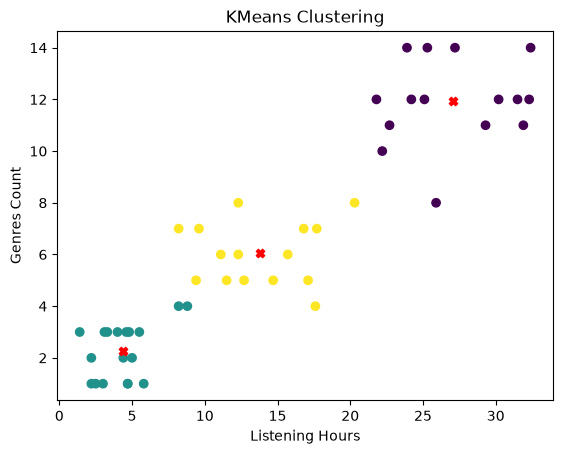

In [190]:
plt.scatter(
    listener_data["weekly_listening_hours"],
    listener_data["followed_genres_count"],
    c=listener_data["cluster"]
)

centers = scaler.inverse_transform(kmeans.cluster_centers_)

plt.scatter(centers[:, 0], centers[:, 1], color="red", marker="X")

plt.xlabel("Listening Hours")
plt.ylabel("Genres Count")
plt.title("KMeans Clustering")
plt.show()

In [193]:
listener_data.groupby("cluster").mean()

,weekly_listening_hours,followed_genres_count
cluster,,
0,27.060000,11.933333
1,4.344444,2.277778
2,13.800000,6.066667


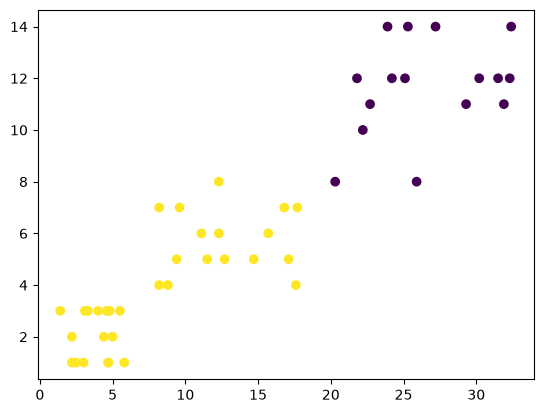

In [194]:
kmeans2 = KMeans(n_clusters=2, random_state=42)
kmeans2.fit(listener_scaled)

listener_data["cluster2"] = kmeans2.labels_

plt.scatter(
    listener_data["weekly_listening_hours"],
    listener_data["followed_genres_count"],
    c=listener_data["cluster2"]
)

plt.show()

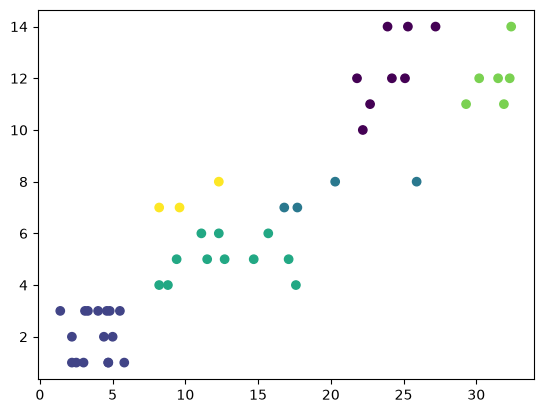

In [196]:
kmeans6 = KMeans(n_clusters=6, random_state=42)

kmeans6.fit(listener_scaled)
listener_data["cluster6"] = kmeans6.labels_

plt.scatter(
    listener_data["weekly_listening_hours"],
    listener_data["followed_genres_count"],
    c=listener_data["cluster6"]
)

plt.show()


In [ ]:
#challenging

# import pandas as pd

# smart_home_data =pd.DataFrame({
#  "temperature_c":
# [-0.6,40.7,17.7,6.4,20.0,8.4,35.5,-3.1,0.1,31.1,-2.6,31.5,-4.6,24.1,
# 33.5,37.2,41.3,18.3,11.6,35.8,13.7,25.3,-4.0,33.0,15.2,21.3,31.6,
# 13.9,37.7,25.5,29.2,31.6,11.5,-4.1,11.9,9.3,38.2,6.9,6.3,37.8,31.5,
# 15.2,38.3,28.3,-1.6,10.1,34.7,24.9,23.9,33.0,24.9,7.6,13.1,11.2,4.4,
# 7.2,26.6,34.9,4.5,31.2,34.1,20.3,12.5,4.5,3.8,10.2,-1.6,4.1,38.2,23.8,
# -3.2,7.9,29.0,38.9,13.7,28.7,33.3,-3.6,33.9,17.5,8.2,22.9,-2.0,2.9,
# 20.1,22.4,5.6,30.1,31.0,11.6,23.0,41.0,8.6,24.4,10.0,38.4,16.8,35.4,
# 3.6,8.3,8.2,22.1,18.1,30.5,-1.8,38.6,8.5,20.8,19.8,18.1,39.7,23.7,
# 14.6,15.6,6.1,41.1,30.4,8.7,8.7,29.0,18.7,-3.1,19.0,12.7,30.3,28.8,
# -1.4,35.4,-2.2,26.0,-1.8,27.9,12.6,4.6,32.1,41.1,23.7,17.6,18.6,-2.4,
# -2.4,6.5,0.3,13.7,4.8,21.9,20.7,-2.8,30.1,-4.9,35.0,23.5,37.4,4.0,4.2,
# -0.5,11.0,22.2,-1.6,5.6,16.8,27.6,18.5,18.5,13.7,-1.1,25.1,19.8,6.0,34.2,
# 5.5,37.8,39.3,17.9,27.0,32.9,10.2,7.2,-4.0,5.2,28.5,40.8,27.3,-3.1,
# 32.6,6.8,4.8,4.8,22.1,-0.3,-3.7,10.4,27.5,3.3,39.7,24.3,-2.3,10.2,
# 26.9,1.1,26.7,24.1,41.2,28.2,2.6,18.5,27.7,5.8,41.6,7.1,1.2,21.8,
# 23.9,20.2,21.8,6.8,-0.8,6.8,16.9,18.0,17.4,6.4,38.3,2.0,11.8,12.0,
# 17.0,22.0,15.2,24.5,26.7,-4.0,18.0,-1.7,25.4,32.0,38.5,12.8,20.1,
# 29.2,7.4,21.8,28.8,3.3,15.1,21.7,38.0,26.0,10.6,24.5,26.7,3.3,17.7,
# 2.3,40.5,15.5,35.6,6.6,29.2,39.9],
#  "household_size":
# [5,1,1,3,1,1,2,1,3,2,1,3,1,4,5,4,6,4,4,1,2,5,5,4,5,2,2,
# 6,1,1,3,1,2,4,1,1,4,2,2,4,2,4,4,4,2,2,3,5,1,1,1,5,4,
# 5,6,3,1,5,6,6,4,5,6,3,4,1,2,4,5,3,3,3,1,6,4,2,1,1,2,6,3,
# 1,3,3,2,6,6,6,1,3,4,1,1,1,6,1,2,3,3,3,1,2,3,3,2,5,
# 2,1,4,6,3,5,2,6,2,6,4,5,4,3,3,6,4,5,4,1,4,4,1,2,4,3,1,3,
# 4,4,6,5,1,2,5,3,2,5,3,4,6,2,5,6,3,6,4,4,3,4,5,4,1,
# 2,4,3,6,3,2,6,6,5,4,3,6,5,6,6,2,6,5,1,1,4,2,6,3,4,2,5,3,
# 1,2,5,2,3,4,2,5,2,1,4,6,4,5,6,4,4,2,2,1,1,3,3,2,5,
# 6,1,5,3,5,3,1,3,1,1,3,4,6,3,5,1,2,6,6,4,1,6,5,4,4,3,1,1,
# 5,5,5,6,5,4,3,4,1,1,4,3,5,4,2,3,3,4,6,3],
#  "ac_units":
# [0,1,2,0,1,3,2,2,0,1,0,3,1,1,3,1,1,0,3,3,1,3,1,2,2,2,1,1,
#  3,2,0,1,0,2,1,3,2,0,3,3,0,0,1,3,3,2,1,1,3,1,2,2,1,
# 3,0,2,2,2,3,3,1,3,3,3,1,2,1,1,0,1,3,1,2,0,2,0,2,0,1,1,3,2,
# 3,0,2,2,2,2,0,0,2,0,2,0,0,0,2,0,0,1,2,1,3,1,0,3,
# 0,3,0,2,1,1,1,2,0,1,1,2,0,0,2,0,2,0,3,2,0,1,3,2,3,0,3,3,1,
# 0,0,3,1,2,3,0,3,1,0,0,1,1,1,1,1,3,2,2,1,3,0,3,3,
# 0,1,1,2,3,0,0,2,0,3,0,1,1,0,3,1,3,0,1,0,0,3,2,3,1,2,0,1,3,
# 1,0,0,0,3,0,2,1,0,1,1,3,1,3,1,3,2,3,3,1,2,1,3,3,
# 1,3,1,2,1,3,1,1,1,2,3,0,2,3,3,1,3,2,1,0,0,0,2,0,1,0,3,1,1,
# 3,3,3,1,3,2,0,0,3,3,3,3,3,2,0,2,0,0,1],
# "wiring_install_year":
# [2002,1988,2002,1983,1988,1976,1979,1985,2010,1979,1976,
# 2006,1984,2012,2003,2018,1979,2020,1987,1996,1975,1994,
# 1984,2006,2019,2004,1976,2023,2006,1985,1987,2001,1979,
# 2016,1997,1981,1989,2013,1992,1989,1975,2011,1977,2020,
# 2008,2001,2005,1985,2004,1979,1985,1989,1996,1989,1978,
# 1993,2003,2018,1989,2015,1998,1983,2009,2005,2023,2002,
# 1982,1989,2006,2006,2016,1982,1988,2016,1990,2003,2002,
# 2023,2021,2005,1984,1997,1982,1996,1975,2019,2015,1996,
# 1981,1976,1999,2005,2005,2017,2013,2012,1996,2012,2002,
# 2012,1975,1995,1989,2012,2006,1984,1988,1988,2005,1988,
# 2012,1989,1980,1990,2011,1977,2018,1989,2000,1982,1975,
# 2002,2013,1979,2011,2017,1987,2007,1998,1987,1984,1993,
# 1979,1983,1994,2021,2004,1995,2002,1995,1982,2009,1992,
# 1991,2003,1989,1977,2003,1999,1986,2014,2022,1985,1984,
# 2023,1987,1989,1981,2012,1992,2000,2003,2010,2009,2000,
# 1995,2019,2011,2020,2003,1980,2020,1981,2004,2016,2012,
# 2005,2000,2011,2016,2022,2023,2003,2001,1977,1979,2001,
# 2005,1997,1988,2018,2019,1996,1979,1976,1986,2019,2018,
# 2020,1995,1999,1992,1998,1975,1992,2012,1986,2002,2018,
# 2006,1991,1984,1975,1982,1990,1988,2003,1999,1982,1984,
# 2015,2023,2007,2006,1997,2004,1980,2023,2004,1986,1989,
# 1991,1987,1985,2001,2007,1976,2000,1976,1997,1983,2019,
# 1989,2017,2013,2001,2018,2006,1985,1986,2007,1995,1996,
# 2014,1998,2020,1997,1981,1994,2016],
#  "outage_risk":
# [0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,
# 0,0,0,0,0,0,0,0,0,0,0,1,0,0,1,0,0,0,0,0,0,0,0,0,0,0,1,0,
# 1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,
# 0,1,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,
# 0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,
# 0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,1,0,0,0,1,0,0,0,0,0,
# 0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,
# 0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,
# 0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,1,0,1,1,1,0,0,0,0,1,
# 0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,
# 0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,1,0,1,0,0,0]
# })

# smart_home_data

ValueError: All arrays must be of the same length

In [ ]:
import pandas as pd

data=({
 "temperature_c":
[-0.6,40.7,17.7,6.4,20.0,8.4,35.5,-3.1,0.1,31.1,-2.6,31.5,-4.6,24.1,
33.5,37.2,41.3,18.3,11.6,35.8,13.7,25.3,-4.0,33.0,15.2,21.3,31.6,
13.9,37.7,25.5,29.2,31.6,11.5,-4.1,11.9,9.3,38.2,6.9,6.3,37.8,31.5,
15.2,38.3,28.3,-1.6,10.1,34.7,24.9,23.9,33.0,24.9,7.6,13.1,11.2,4.4,
7.2,26.6,34.9,4.5,31.2,34.1,20.3,12.5,4.5,3.8,10.2,-1.6,4.1,38.2,23.8,
-3.2,7.9,29.0,38.9,13.7,28.7,33.3,-3.6,33.9,17.5,8.2,22.9,-2.0,2.9,
20.1,22.4,5.6,30.1,31.0,11.6,23.0,41.0,8.6,24.4,10.0,38.4,16.8,35.4,
3.6,8.3,8.2,22.1,18.1,30.5,-1.8,38.6,8.5,20.8,19.8,18.1,39.7,23.7,
14.6,15.6,6.1,41.1,30.4,8.7,8.7,29.0,18.7,-3.1,19.0,12.7,30.3,28.8,
-1.4,35.4,-2.2,26.0,-1.8,27.9,12.6,4.6,32.1,41.1,23.7,17.6,18.6,-2.4,
-2.4,6.5,0.3,13.7,4.8,21.9,20.7,-2.8,30.1,-4.9,35.0,23.5,37.4,4.0,4.2,
-0.5,11.0,22.2,-1.6,5.6,16.8,27.6,18.5,18.5,13.7,-1.1,25.1,19.8,6.0,34.2,
5.5,37.8,39.3,17.9,27.0,32.9,10.2,7.2,-4.0,5.2,28.5,40.8,27.3,-3.1,
32.6,6.8,4.8,4.8,22.1,-0.3,-3.7,10.4,27.5,3.3,39.7,24.3,-2.3,10.2,
26.9,1.1,26.7,24.1,41.2,28.2,2.6,18.5,27.7,5.8,41.6,7.1,1.2,21.8,
23.9,20.2,21.8,6.8,-0.8,6.8,16.9,18.0,17.4,6.4,38.3,2.0,11.8,12.0,
17.0,22.0,15.2,24.5,26.7,-4.0,18.0,-1.7,25.4,32.0,38.5,12.8,20.1,
29.2,7.4,21.8,28.8,3.3,15.1,21.7,38.0,26.0,10.6,24.5,26.7,3.3,17.7,
2.3,40.5,15.5,35.6,6.6,29.2,39.9],
 "household_size":
[5,1,1,3,1,1,2,1,3,2,1,3,1,4,5,4,6,4,4,1,2,5,5,4,5,2,2,
6,1,1,3,1,2,4,1,1,4,2,2,4,2,4,4,4,2,2,3,5,1,1,1,5,4,
5,6,3,1,5,6,6,4,5,6,3,4,1,2,4,5,3,3,3,1,6,4,2,1,1,2,6,3,
1,3,3,2,6,6,6,1,3,4,1,1,1,6,1,2,3,3,3,1,2,3,3,2,5,
2,1,4,6,3,5,2,6,2,6,4,5,4,3,3,6,4,5,4,1,4,4,1,2,4,3,1,3,
4,4,6,5,1,2,5,3,2,5,3,4,6,2,5,6,3,6,4,4,3,4,5,4,1,
2,4,3,6,3,2,6,6,5,4,3,6,5,6,6,2,6,5,1,1,4,2,6,3,4,2,5,3,
1,2,5,2,3,4,2,5,2,1,4,6,4,5,6,4,4,2,2,1,1,3,3,2,5,
6,1,5,3,5,3,1,3,1,1,3,4,6,3,5,1,2,6,6,4,1,6,5,4,4,3,1,1,
5,5,5,6,5,4,3,4,1,1,4,3,5,4,2,3,3,4,6,3],
 "ac_units":
[0,1,2,0,1,3,2,2,0,1,0,3,1,1,3,1,1,0,3,3,1,3,1,2,2,2,1,1,
 3,2,0,1,0,2,1,3,2,0,3,3,0,0,1,3,3,2,1,1,3,1,2,2,1,
3,0,2,2,2,3,3,1,3,3,3,1,2,1,1,0,1,3,1,2,0,2,0,2,0,1,1,3,2,
3,0,2,2,2,2,0,0,2,0,2,0,0,0,2,0,0,1,2,1,3,1,0,3,
0,3,0,2,1,1,1,2,0,1,1,2,0,0,2,0,2,0,3,2,0,1,3,2,3,0,3,3,1,
0,0,3,1,2,3,0,3,1,0,0,1,1,1,1,1,3,2,2,1,3,0,3,3,
0,1,1,2,3,0,0,2,0,3,0,1,1,0,3,1,3,0,1,0,0,3,2,3,1,2,0,1,3,
1,0,0,0,3,0,2,1,0,1,1,3,1,3,1,3,2,3,3,1,2,1,3,3,
1,3,1,2,1,3,1,1,1,2,3,0,2,3,3,1,3,2,1,0,0,0,2,0,1,0,3,1,1,
3,3,3,1,3,2,0,0,3,3,3,3,3,2,0,2,0,0,1],
"wiring_install_year":
[2002,1988,2002,1983,1988,1976,1979,1985,2010,1979,1976,
2006,1984,2012,2003,2018,1979,2020,1987,1996,1975,1994,
1984,2006,2019,2004,1976,2023,2006,1985,1987,2001,1979,
2016,1997,1981,1989,2013,1992,1989,1975,2011,1977,2020,
2008,2001,2005,1985,2004,1979,1985,1989,1996,1989,1978,
1993,2003,2018,1989,2015,1998,1983,2009,2005,2023,2002,
1982,1989,2006,2006,2016,1982,1988,2016,1990,2003,2002,
2023,2021,2005,1984,1997,1982,1996,1975,2019,2015,1996,
1981,1976,1999,2005,2005,2017,2013,2012,1996,2012,2002,
2012,1975,1995,1989,2012,2006,1984,1988,1988,2005,1988,
2012,1989,1980,1990,2011,1977,2018,1989,2000,1982,1975,
2002,2013,1979,2011,2017,1987,2007,1998,1987,1984,1993,
1979,1983,1994,2021,2004,1995,2002,1995,1982,2009,1992,
1991,2003,1989,1977,2003,1999,1986,2014,2022,1985,1984,
2023,1987,1989,1981,2012,1992,2000,2003,2010,2009,2000,
1995,2019,2011,2020,2003,1980,2020,1981,2004,2016,2012,
2005,2000,2011,2016,2022,2023,2003,2001,1977,1979,2001,
2005,1997,1988,2018,2019,1996,1979,1976,1986,2019,2018,
2020,1995,1999,1992,1998,1975,1992,2012,1986,2002,2018,
2006,1991,1984,1975,1982,1990,1988,2003,1999,1982,1984,
2015,2023,2007,2006,1997,2004,1980,2023,2004,1986,1989,
1991,1987,1985,2001,2007,1976,2000,1976,1997,1983,2019,
1989,2017,2013,2001,2018,2006,1985,1986,2007,1995,1996,
2014,1998,2020,1997,1981,1994,2016],
 "outage_risk":
[0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,
0,0,0,0,0,0,0,0,0,0,0,1,0,0,1,0,0,0,0,0,0,0,0,0,0,0,1,0,
1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,
0,1,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,
0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,
0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,1,0,0,0,1,0,0,0,0,0,
0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,
0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,
0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,1,0,1,1,1,0,0,0,0,1,
0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,
0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,1,0,1,0,0,0]
})

for col, values in data.items():
    print(col, len(values))

temperature_c 260
household_size 260
ac_units 260
wiring_install_year 260
outage_risk 303
